Titanic Passenger Survival Analysis (Pandas)
Goal: Clean the Titanic passenger dataset and use grouping to find which passenger groups had higher survival rates.
Questions to answer
1. Did women survive more often than men?
2. Did passenger class make a difference to survival?
3. Was survival different across age groups?
A survival rate is the percentage of passengers in a group who survived. These results show patterns in this dataset; they do not prove that sex, class, or age alone caused survival.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("titanic")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
print("Shape:", df.shape)
display(df.head())

print("\\nDataset information:")
df.info()

print("\\nSummary statistics:")
display(df.describe(include="all").T)

Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


\nDataset information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB
\nSummary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
print("Missing values in each column:")
display(df.isna().sum().sort_values(ascending=False))

print("Exact duplicate rows:", df.duplicated().sum())

Missing values in each column:


deck           688
age            177
embarked         2
embark_town      2
sex              0
pclass           0
survived         0
fare             0
parch            0
sibsp            0
class            0
adult_male       0
who              0
alive            0
alone            0
dtype: int64

Exact duplicate rows: 107


In [4]:
df_clean = df.copy()

# Fill age using the median for each passenger class and sex
df_clean["age"] = df_clean["age"].fillna(
    df_clean.groupby(["class", "sex"], observed=False)["age"]
    .transform("median")
)

# Drop deck because it is mostly missing
df_clean = df_clean.drop(columns=["deck"])

# Fill embarked with its most common value
most_common_embarked = df_clean["embarked"].mode()[0]
df_clean["embarked"] = df_clean["embarked"].fillna(most_common_embarked)

# Set suitable data types
df_clean["survived"] = df_clean["survived"].astype("int64")
df_clean["pclass"] = df_clean["pclass"].astype("int64")
df_clean["sex"] = df_clean["sex"].astype("category")
df_clean["class"] = df_clean["class"].astype("category")
df_clean["embarked"] = df_clean["embarked"].astype("category")

print("Missing values after cleaning:")
display(df_clean.isna().sum().sort_values(ascending=False))

print("Shape before cleaning:", df.shape)
print("Shape after cleaning:", df_clean.shape)
print("Exact duplicate rows (not automatically removed):", df_clean.duplicated().sum())

Missing values after cleaning:


embark_town    2
survived       0
sex            0
age            0
sibsp          0
pclass         0
parch          0
fare           0
class          0
embarked       0
who            0
adult_male     0
alive          0
alone          0
dtype: int64

Shape before cleaning: (891, 15)
Shape after cleaning: (891, 14)
Exact duplicate rows (not automatically removed): 118


In [5]:
# Survival rate by sex
survival_by_sex = (
    df_clean.groupby("sex", observed=False)["survived"]
    .agg(["mean", "count", "sum"])
    .rename(columns={"mean": "survival_rate", "count": "passengers", "sum": "survivors"})
    .sort_values("survival_rate", ascending=False)
)
survival_by_sex["survival_rate"] *= 100
display(survival_by_sex.round(2))

,survival_rate,passengers,survivors
sex,,,
female,74.20,314,233
male,18.89,577,109


In [6]:
# Survival rate by passenger class
survival_by_class = (
    df_clean.groupby("class", observed=False)["survived"]
    .agg(["mean", "count", "sum"])
    .rename(columns={"mean": "survival_rate", "count": "passengers", "sum": "survivors"})
    .sort_values("survival_rate", ascending=False)
)
survival_by_class["survival_rate"] *= 100
display(survival_by_class.round(2))

,survival_rate,passengers,survivors
class,,,
First,62.96,216,136
Second,47.28,184,87
Third,24.24,491,119


In [7]:
# Create age groups
age_bins = [0, 12, 18, 35, 60, 100]
age_labels = ["Child (0-12)", "Teen (13-18)", "Young adult (19-35)",
              "Adult (36-60)", "Senior (61+)"]

df_clean["age_group"] = pd.cut(
    df_clean["age"], bins=age_bins, labels=age_labels, include_lowest=True
)

survival_by_age = (
    df_clean.groupby("age_group", observed=False)["survived"]
    .agg(["mean", "count", "sum"])
    .rename(columns={"mean": "survival_rate", "count": "passengers", "sum": "survivors"})
)
survival_by_age["survival_rate"] *= 100
display(survival_by_age.round(2))

,survival_rate,passengers,survivors
age_group,,,
Child (0-12),57.97,69,40
Teen (13-18),42.86,70,30
Young adult (19-35),35.80,514,184
Adult (36-60),38.43,216,83
Senior (61+),22.73,22,5


In [8]:
def best_and_lowest(table):
    best_group = table["survival_rate"].idxmax()
    lowest_group = table["survival_rate"].idxmin()
    best_rate = table.loc[best_group, "survival_rate"]
    lowest_rate = table.loc[lowest_group, "survival_rate"]
    return best_group, best_rate, lowest_group, lowest_rate

best_sex, best_sex_rate, low_sex, low_sex_rate = best_and_lowest(survival_by_sex)
best_class, best_class_rate, low_class, low_class_rate = best_and_lowest(survival_by_class)
best_age, best_age_rate, low_age, low_age_rate = best_and_lowest(survival_by_age)

print(f"Finding 1 - Sex: {best_sex} passengers had the highest survival rate "
      f"({best_sex_rate:.1f}%), compared with {low_sex} passengers ({low_sex_rate:.1f}%).")

print(f"Finding 2 - Class: {best_class} class had the highest survival rate "
      f"({best_class_rate:.1f}%), while {low_class} class had the lowest "
      f"({low_class_rate:.1f}%).")

print(f"Finding 3 - Age: The {best_age} group had the highest survival rate "
      f"({best_age_rate:.1f}%), while the {low_age} group had the lowest "
      f"({low_age_rate:.1f}%).")

Finding 1 - Sex: female passengers had the highest survival rate (74.2%), compared with male passengers (18.9%).
Finding 2 - Class: First class had the highest survival rate (63.0%), while Third class had the lowest (24.2%).
Finding 3 - Age: The Child (0-12) group had the highest survival rate (58.0%), while the Senior (61+) group had the lowest (22.7%).


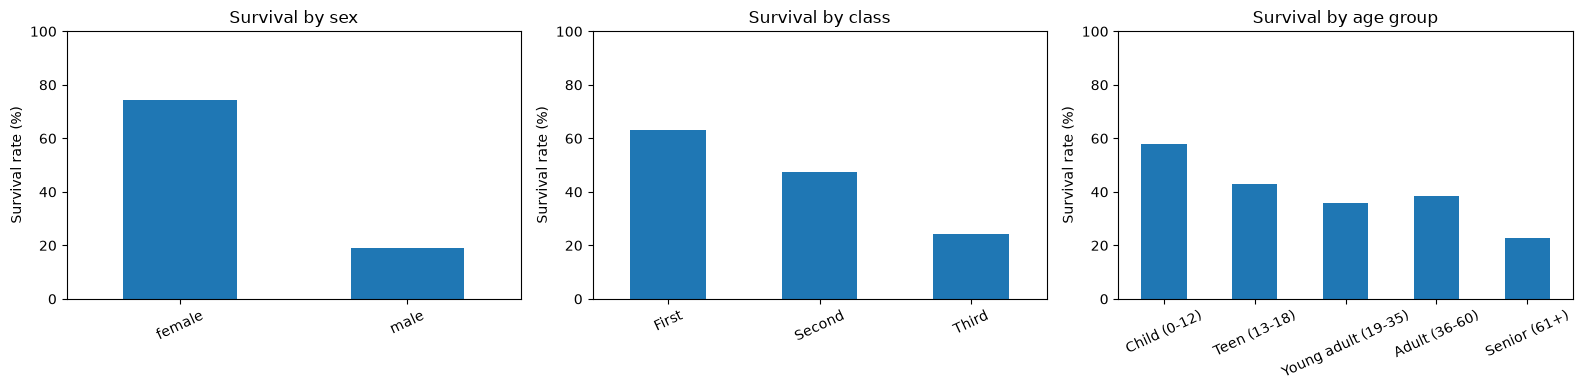

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

survival_by_sex["survival_rate"].plot(kind="bar", ax=axes[0], title="Survival by sex", ylabel="Survival rate (%)")
survival_by_class["survival_rate"].plot(kind="bar", ax=axes[1], title="Survival by class", ylabel="Survival rate (%)")
survival_by_age["survival_rate"].plot(kind="bar", ax=axes[2], title="Survival by age group", ylabel="Survival rate (%)")

for ax in axes:
    ax.set_ylim(0, 100)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()